In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# IMPORT
import sys
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import random_split
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import numpy as np
import os
import torch
import torch.nn as nn
import torch.optim as optim
import copy
import re
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import os
import matplotlib.pyplot as plt



root_path = "/content/drive/MyDrive/Action Recognition on UCF101"
src_path = os.path.join(root_path, "src")
split_path = os.path.join(root_path, "ucfTrainTestlist")

if src_path not in sys.path:
    sys.path.append(src_path)

#from dataset import UCF101Dataset
#from dataset import get_datasets
from dataset2 import UCF101DatasetFast
from dataset2 import get_datasets
from models import ResNet2D_Baseline, CustomCNN, ViViT_Pretrained
from training import train_one_epoch, validate, get_next_run_id

In [ ]:
annotation_file_train=os.path.join(split_path, "trainlist01.txt")
annotation_file_test=os.path.join(split_path, "testlist01.txt")
class_ind_file=os.path.join(split_path, "classInd.txt")

In [ ]:
zip_path_drive = "/content/drive/MyDrive/Action Recognition on UCF101/UCF-101-JPG-zipped.zip"
local_root = "/content/data"
final_data_path = os.path.join(local_root, "temp_jpg_224")
if not os.path.exists(final_data_path):

    os.makedirs(local_root, exist_ok=True)

    !unzip -q -o "{zip_path_drive}" -d "{local_root}"

    print(f"Done! Data ready in: {final_data_path}")
else:
    print(f"Data already in {final_data_path}.")

# VERIFY
if os.path.exists(final_data_path):
    num_classes = len(os.listdir(final_data_path))
    print(f"Found {num_classes} classes in {final_data_path}")
else:
    print("Something gone wrong. Check zip name or path.")

Done! Data ready in: /content/data/temp_jpg_224
Found 101 classes in /content/data/temp_jpg_224


In [ ]:
# HYPERPARAMETERS
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16
NUM_CLASSES = 101
FRAMES = 16

print(f"Using device: {DEVICE}")

Using device: cuda


In [ ]:
data_root="/content/data/temp_jpg_224"
annotation_file_train=os.path.join(split_path, "trainlist01.txt")
annotation_file_test=os.path.join(split_path, "testlist01.txt")
class_ind_file=os.path.join(split_path, "classInd.txt")
config = {
    "DATA_ROOT" : data_root,
    "TRAIN_ANNOTATION_FILE": annotation_file_train,
    "TEST_ANNOTATION_FILE" : annotation_file_test,
    "CLASS_IND_FILE": class_ind_file,
    "FRAMES_PER_CLIP":16,
    "RESIZE_HEIGHT" : 224,
    "RESIZE_WIDTH" : 224
}
print("Loading Datasets...")
train_dataset, val_dataset, test_dataset = get_datasets(config)

Loading Datasets...
--------------------------------------------------
GROUP-BASED SPLIT SUMMARY:
Train samples: 7675, ['JumpingJack_g17', 'RopeClimbing_g22', 'HighJump_g18', 'MoppingFloor_g12', 'PlayingFlute_g08', 'Nunchucks_g17', 'MilitaryParade_g23', 'UnevenBars_g23', 'HighJump_g22', 'WritingOnBoard_g23', 'Archery_g11', 'TennisSwing_g14', 'HeadMassage_g18', 'ApplyLipstick_g09', 'Kayaking_g17', 'BabyCrawling_g10', 'Swing_g10', 'CricketShot_g09', 'ApplyEyeMakeup_g21', 'RockClimbingIndoor_g20', 'FrisbeeCatch_g11', 'HorseRace_g09', 'RockClimbingIndoor_g21', 'PoleVault_g25', 'HorseRiding_g15', 'VolleyballSpiking_g20', 'FrisbeeCatch_g17', 'HorseRiding_g12', 'TaiChi_g08', 'WalkingWithDog_g12', 'BlowDryHair_g25', 'CricketBowling_g25', 'PoleVault_g15', 'IceDancing_g23', 'TaiChi_g17', 'CleanAndJerk_g25', 'VolleyballSpiking_g14', 'BreastStroke_g21', 'YoYo_g13', 'BreastStroke_g15', 'YoYo_g22', 'Diving_g17', 'BoxingSpeedBag_g19', 'FrisbeeCatch_g08', 'PlayingDhol_g22', 'PlayingGuitar_g20', 'Socce

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2) # Shuffle False per Val
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

In [ ]:
from tqdm import tqdm
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(loader, desc="Training")

    for batch_videos, batch_labels in loop:
        # 1. Sposta i dati sul device
        # Original Shape: [Batch, 3, 16, 224, 224] (B, C, T, H, W)
        videos = batch_videos.to(device)
        labels = batch_labels.to(device)

        # 2. FIX SHAPE: Permute da (B, C, T, H, W) -> (B, T, C, H, W)
        # VideoMAE vuole i frame (T) prima dei canali colore (C)
        videos = videos.permute(0, 2, 1, 3, 4)

        optimizer.zero_grad()

        # 3. FORWARD: VideoMAE restituisce un oggetto VideoClassifierOutput
        outputs = model(videos)

        # Estraiamo i logits per il calcolo della loss e delle predizioni
        logits = outputs.logits # Shape: [Batch, 101]

        # 4. LOSS & BACKWARD
        loss = criterion(logits, labels)
        loss.backward()

        # 5. OPTIMIZER STEP
        optimizer.step()

        # Statistiche
        running_loss += loss.item()
        _, predicted = torch.max(logits, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        loop.set_postfix(loss=loss.item(), acc=100 * correct / total)

    avg_loss = running_loss / len(loader)
    avg_acc = 100 * correct / total
    return avg_loss, avg_acc




def validate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_videos, batch_labels in tqdm(loader, desc="Validation"):
            videos = batch_videos.to(device)
            labels = batch_labels.to(device)
            videos = videos.permute(0, 2, 1, 3, 4)
            outputs = model(videos)
            logits = outputs.logits
            loss = criterion(logits, labels)

            running_loss += loss.item()
            _, predicted = torch.max(logits, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    avg_loss = running_loss / len(loader)
    avg_acc = 100 * correct / total
    return avg_loss, avg_acc

 EXPERIMENT STARTED: ViViT_Transformer_FineTuning
 MODE: Transformer Fine-Tuning
 OUTPUT FOLDER: /content/drive/MyDrive/Action Recognition on UCF101/experiments/ViViT_Transformer_FineTuning/Run_09


Some weights of VideoMAEForVideoClassification were not initialized from the model checkpoint at MCG-NJU/videomae-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/50


Validation: 100%|██████████| 117/117 [00:44<00:00,  2.60it/s]


 -> Train Loss: 3.7806 | Acc: 27.19%
 -> Val Loss:   3.0242 | Acc: 40.39%
    >>> New Best Validation Accuracy! Model saved.
Epoch 2/50


Validation: 100%|██████████| 117/117 [00:45<00:00,  2.60it/s]


... (53 outputs left out)

Validation: 100%|██████████| 117/117 [00:45<00:00,  2.59it/s]


 -> Train Loss: 0.7827 | Acc: 99.93%
 -> Val Loss:   1.8076 | Acc: 72.07%
!!! No improvement. Patience: 11/12
Epoch 30/50


Validation: 100%|██████████| 117/117 [00:45<00:00,  2.59it/s]


 -> Train Loss: 0.8006 | Acc: 99.56%
 -> Val Loss:   1.4374 | Acc: 81.31%
!!! No improvement. Patience: 12/12

EARLY STOPPING TRIGGERED.

 TRAINING COMPLETE


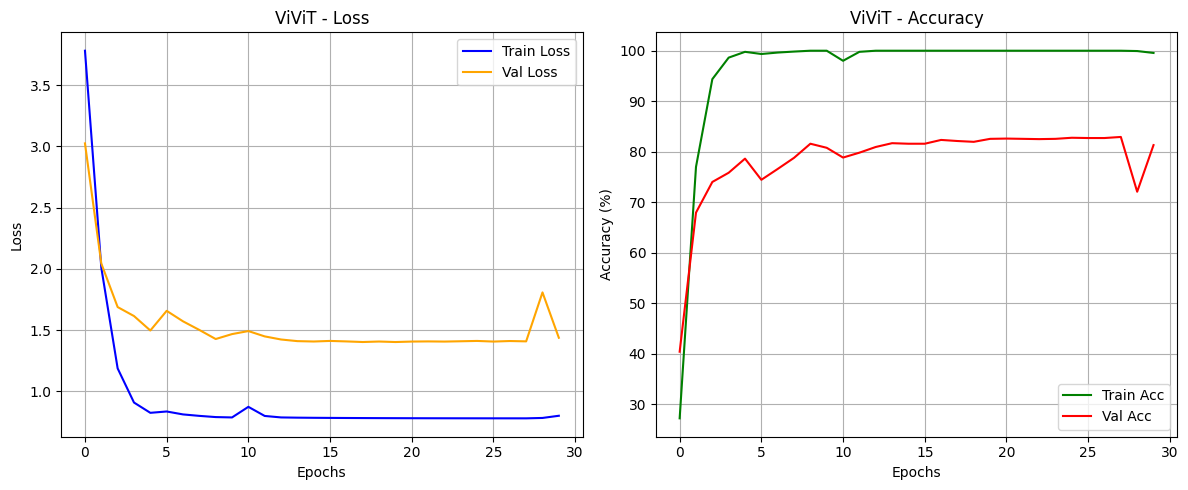

In [23]:
from transformers import VideoMAEForVideoClassification, VideoMAEConfig




VARIANT_NAME = "ViViT_Transformer_FineTuning"
EXPERIMENTS_ROOT = os.path.join(root_path, "experiments", VARIANT_NAME)
RUN_ID = get_next_run_id(EXPERIMENTS_ROOT)
checkpoint_dir = os.path.join(EXPERIMENTS_ROOT, RUN_ID)
best_model_path = os.path.join(checkpoint_dir, "best_model.pth")

os.makedirs(checkpoint_dir, exist_ok=True)

PATIENCE = 12
EARLY_STOPPING_DELTA = 0.0005
LEARNING_RATE = 2e-5
NUM_EPOCHS = 50

print(f"==================================================")
print(f" EXPERIMENT STARTED: {VARIANT_NAME}")
print(f" MODE: Transformer Fine-Tuning")
print(f" OUTPUT FOLDER: {checkpoint_dir}")
print(f"==================================================")

model_ckpt = "MCG-NJU/videomae-base"

model = VideoMAEForVideoClassification.from_pretrained(
    model_ckpt,
    num_labels=NUM_CLASSES,
    ignore_mismatched_sizes=True
).to(DEVICE)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)

scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

train_loss_hist, val_loss_hist = [], []
train_acc_hist, val_acc_hist = [], []

best_val_acc = 0.0
min_val_loss = float('inf')
early_stopping_counter = 0

for epoch in range(NUM_EPOCHS):
    print(f"Epoch {epoch+1}/{NUM_EPOCHS}")

    # (permutation in the model forward) (B, C, T, H, W) -> (B, T, C, H, W)

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
    val_loss, val_acc = validate(model, val_loader, criterion, DEVICE)
    scheduler.step()
    train_loss_hist.append(train_loss)
    val_loss_hist.append(val_loss)
    train_acc_hist.append(train_acc)
    val_acc_hist.append(val_acc)

    print(f" -> Train Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
    print(f" -> Val Loss:   {val_loss:.4f} | Acc: {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), best_model_path)
        print(f"    >>> New Best Validation Accuracy! Model saved.")

    if val_loss < (min_val_loss - EARLY_STOPPING_DELTA):
        min_val_loss = val_loss
        early_stopping_counter = 0
    else:
        early_stopping_counter += 1
        print(f"!!! No improvement. Patience: {early_stopping_counter}/{PATIENCE}")
        if early_stopping_counter >= PATIENCE:
            print(f"\nEARLY STOPPING TRIGGERED.")
            break

print("\n" + "="*50)
print(" TRAINING COMPLETE")
print("="*50)


plt.figure(figsize=(12, 5))


plt.subplot(1, 2, 1)
plt.plot(train_loss_hist, label='Train Loss', color='blue')
plt.plot(val_loss_hist, label='Val Loss', color='orange')
plt.title(f'ViViT - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)


plt.subplot(1, 2, 2)
plt.plot(train_acc_hist, label='Train Acc', color='green')
plt.plot(val_acc_hist, label='Val Acc', color='red')
plt.title(f'ViViT - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(checkpoint_dir, "training_plots.png"))
plt.show()


In [24]:
# Check the first 10 labels of the test set
test_labels = [test_dataset.samples[i][1] for i in range(10)]
unique_test_labels = set([s[1] for s in test_dataset.samples])

print(f"First 10 test labels: {test_labels}")
print(f"Number of unique classes in test set: {len(unique_test_labels)}")
print(f"Unique labels found: {unique_test_labels}")

First 10 test labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Number of unique classes in test set: 1
Unique labels found: {0}


In [25]:
# RECOVER CLASS MAPPING
class_to_idx = {}

for path, label in train_dataset.samples:
    class_name = os.path.basename(os.path.dirname(path))
    class_to_idx[class_name] = label

print(f"Mapping reconstructed for {len(class_to_idx)} classes.")

# APPLY MAPPING TO TEST DATASET (REPAIR)
# This step ensures that the test labels are synchronized with the training labels
repaired_samples = []
for path, old_label in test_dataset.samples:
    class_name = os.path.basename(os.path.dirname(path))

    if class_name in class_to_idx:
        new_label = class_to_idx[class_name]
        repaired_samples.append((path, new_label))
    else:
        # Fallback: keep the original label if the class is not found in the training set
        repaired_samples.append((path, old_label))

# Update the test dataset samples with the corrected labels
test_dataset.samples = repaired_samples

# FINAL VERIFICATION
unique_labels = set([s[1] for s in test_dataset.samples])
print(f"Verification complete: Found {len(unique_labels)} unique classes in the Test Set.")

Mapping reconstructed for 101 classes.
Verification complete: Found 101 unique classes in the Test Set.


In [27]:
def perform_final_evaluation(model, test_loader, best_model_path, train_dataset, device):
    print("--- STARTING FINAL EXTENDED EVALUATION ---")

    idx_to_class = {}
    for path, label in train_dataset.samples:
        class_name = os.path.basename(os.path.dirname(path))
        if label not in idx_to_class:
            idx_to_class[label] = class_name


    model.load_state_dict(torch.load(best_model_path))
    model.to(device)
    model.eval()

    all_preds = []
    all_labels = []

    print("Running inference on test set...")
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            inputs = inputs.permute(0, 2, 1, 3, 4)
            outputs = model(inputs)
            logits = outputs.logits
            _, preds = torch.max(logits, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)


    final_acc = (all_preds == all_labels).mean() * 100
    print(f"\nFINAL TEST ACCURACY: {final_acc:.2f}%")
    print("-" * 40)


    target_names = [idx_to_class[i] for i in sorted(idx_to_class.keys())]
    full_report = classification_report(all_labels, all_preds, target_names=target_names, digits=4)
    print("\nCLASSIFICATION REPORT:")
    print(full_report)


    cm = confusion_matrix(all_labels, all_preds)
    per_class_acc = np.divide(cm.diagonal(), cm.sum(axis=1),
                              out=np.zeros_like(cm.diagonal(), dtype=float),
                              where=cm.sum(axis=1)!=0)


    performance_df = pd.DataFrame({
        'Class_Name': [idx_to_class.get(i, f"Unknown_{i}") for i in range(len(per_class_acc))],
        'Accuracy': per_class_acc
    }).sort_values(by='Accuracy', ascending=True)

    print("\nTOP 5 MOST DIFFICULT CLASSES (Lowest Accuracy):")

    print(performance_df.head(5).to_string(index=False, formatters={'Accuracy': '{:,.2%}'.format}))

    print("\nTOP 5 BEST PERFORMING CLASSES (Highest Accuracy):")
    print(performance_df.tail(5).sort_values(by='Accuracy', ascending=False).to_string(index=False, formatters={'Accuracy': '{:,.2%}'.format}))

    return all_labels, all_preds, performance_df

labels, preds, class_stats = perform_final_evaluation(model, test_loader, best_model_path, train_dataset, DEVICE)

--- STARTING FINAL EXTENDED EVALUATION ---
Running inference on test set...

FINAL TEST ACCURACY: 79.22%
----------------------------------------

CLASSIFICATION REPORT:
                    precision    recall  f1-score   support

    ApplyEyeMakeup     0.7308    0.8636    0.7917        44
     ApplyLipstick     0.7037    0.5938    0.6441        32
           Archery     0.6923    0.6585    0.6750        41
      BabyCrawling     0.8718    0.9714    0.9189        35
       BalanceBeam     0.8235    0.9032    0.8615        31
      BandMarching     0.9318    0.9535    0.9425        43
     BaseballPitch     0.9118    0.7209    0.8052        43
        Basketball     0.5400    0.7714    0.6353        35
    BasketballDunk     0.9024    1.0000    0.9487        37
        BenchPress     1.0000    0.9792    0.9895        48
            Biking     0.9655    0.7368    0.8358        38
         Billiards     1.0000    1.0000    1.0000        40
       BlowDryHair     0.6129    0.5000    0.5507